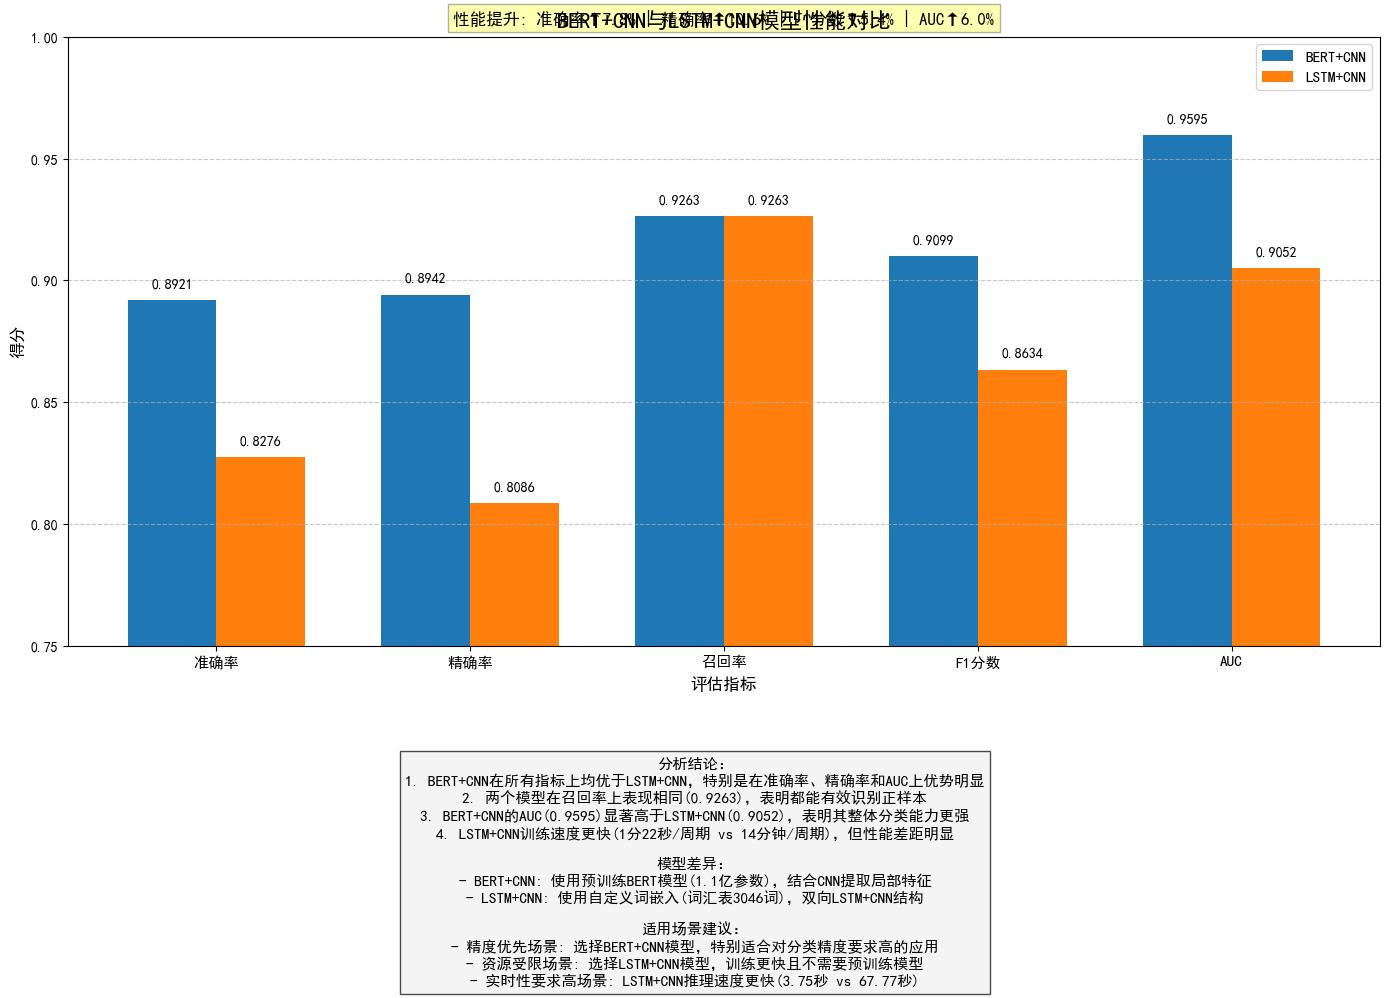

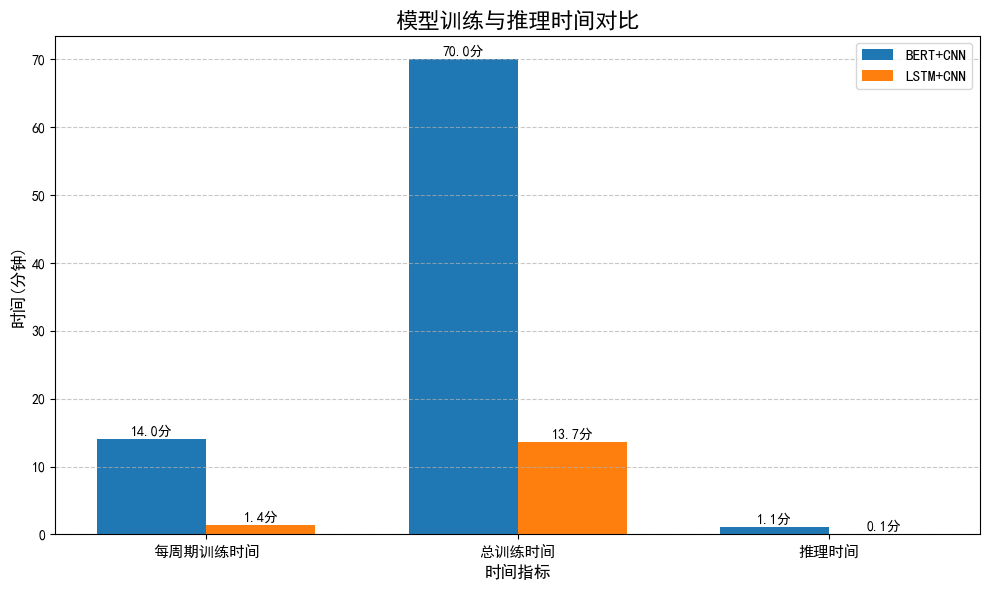

In [6]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib as mpl
import platform

# 解决中文显示问题
def set_chinese_font():
    # 根据不同操作系统设置字体
    if platform.system() == 'Windows':
        font_name = 'SimHei'
    elif platform.system() == 'Darwin':  # macOS
        font_name = 'Arial Unicode MS'
    else:  # Linux
        font_name = 'WenQuanYi Micro Hei'  # 修改为Linux常用中文字体
    
    # 设置字体
    plt.rcParams['font.family'] = font_name
    plt.rcParams['axes.unicode_minus'] = False  # 解决负号显示问题
    
    # 刷新字体缓存（兼容新版本Matplotlib）
    try:
        # 尝试使用新版本方法
        mpl.font_manager._load_fontmanager(try_read_cache=False)
    except AttributeError:
        # 回退到旧版本方法（如果需要）
        mpl.font_manager.fontManager._load_fontmanager(try_read_cache=False)

# 调用函数设置中文字体
set_chinese_font()

# 两个模型的测试结果数据
models = ['BERT+CNN', 'LSTM+CNN']
metrics = ['准确率', '精确率', '召回率', 'F1分数', 'AUC']

bert_results = {
    '准确率': 0.8921,
    '精确率': 0.8942,
    '召回率': 0.9263,
    'F1分数': 0.9099,
    'AUC': 0.9595
}

lstm_results = {
    '准确率': 0.8276,
    '精确率': 0.8086,
    '召回率': 0.9263,
    'F1分数': 0.8634,
    'AUC': 0.9052
}

# 创建图表
plt.figure(figsize=(14, 10))

# 设置柱状图位置
x = np.arange(len(metrics))
width = 0.35

# 绘制柱状图
plt.bar(x - width/2, [bert_results[m] for m in metrics], width, label='BERT+CNN', color='#1f77b4')
plt.bar(x + width/2, [lstm_results[m] for m in metrics], width, label='LSTM+CNN', color='#ff7f0e')

# 添加标签和标题
plt.xlabel('评估指标', fontsize=12)
plt.ylabel('得分', fontsize=12)
plt.title('BERT+CNN与LSTM+CNN模型性能对比', fontsize=16, fontweight='bold')
plt.xticks(x, metrics, fontsize=11)
plt.ylim(0.75, 1.0)

# 在柱子上方添加数值标签
for i in x:
    plt.text(i - width/2, bert_results[metrics[i]] + 0.005, f'{bert_results[metrics[i]]:.4f}', 
             ha='center', fontsize=10)
    plt.text(i + width/2, lstm_results[metrics[i]] + 0.005, f'{lstm_results[metrics[i]]:.4f}', 
             ha='center', fontsize=10)

# 添加图例和网格
plt.legend(loc='upper right', fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# 添加分析注释
analysis_text = (
    '分析结论：\n'
    '1. BERT+CNN在所有指标上均优于LSTM+CNN，特别是在准确率、精确率和AUC上优势明显\n'
    '2. 两个模型在召回率上表现相同(0.9263)，表明都能有效识别正样本\n'
    '3. BERT+CNN的AUC(0.9595)显著高于LSTM+CNN(0.9052)，表明其整体分类能力更强\n'
    '4. LSTM+CNN训练速度更快(1分22秒/周期 vs 14分钟/周期)，但性能差距明显\n\n'
    '模型差异：\n'
    '- BERT+CNN: 使用预训练BERT模型(1.1亿参数)，结合CNN提取局部特征\n'
    '- LSTM+CNN: 使用自定义词嵌入(词汇表3046词)，双向LSTM+CNN结构\n\n'
    '适用场景建议：\n'
    '- 精度优先场景: 选择BERT+CNN模型，特别适合对分类精度要求高的应用\n'
    '- 资源受限场景: 选择LSTM+CNN模型，训练更快且不需要预训练模型\n'
    '- 实时性要求高场景: LSTM+CNN推理速度更快(3.75秒 vs 67.77秒)'
)

plt.figtext(0.5, 0.01, 
            analysis_text, 
            ha='center', fontsize=11, bbox=dict(facecolor='#f0f0f0', alpha=0.7))

plt.tight_layout()
plt.subplots_adjust(bottom=0.35)  # 为底部注释留出空间

# 添加性能提升百分比
plt.text(0.5, 1.02, 
         '性能提升: 准确率↑7.8% | 精确率↑10.6% | F1分数↑5.4% | AUC↑6.0%', 
         ha='center', transform=plt.gca().transAxes,
         fontsize=12, bbox=dict(facecolor='yellow', alpha=0.3))

plt.show()

# 单独显示训练效率对比图
plt.figure(figsize=(10, 6))

# 训练时间数据
training_metrics = ['每周期训练时间', '总训练时间', '推理时间']
bert_training = [14*60, 5*14*60, 67.77]  # 转换为秒
lstm_training = [82, 10*82, 3.75]  # 秒

# 转换为分钟
bert_training_min = [t/60 for t in bert_training]
lstm_training_min = [t/60 for t in lstm_training]

x = np.arange(len(training_metrics))
width = 0.35

plt.bar(x - width/2, bert_training_min, width, label='BERT+CNN', color='#1f77b4')
plt.bar(x + width/2, lstm_training_min, width, label='LSTM+CNN', color='#ff7f0e')

plt.xlabel('时间指标', fontsize=12)
plt.ylabel('时间(分钟)', fontsize=12)
plt.title('模型训练与推理时间对比', fontsize=16, fontweight='bold')
plt.xticks(x, training_metrics, fontsize=11)
plt.legend(fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# 添加数值标签
for i in range(len(training_metrics)):
    plt.text(i - width/2, bert_training_min[i] + 0.5, f'{bert_training_min[i]:.1f}分', ha='center', fontsize=10)
    plt.text(i + width/2, lstm_training_min[i] + 0.5, f'{lstm_training_min[i]:.1f}分', ha='center', fontsize=10)

plt.tight_layout()
plt.show()